In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
import joblib
import xgboost as xgb
import lightgbm as lgb
import catboost as ctb

In [ ]:
PATH_1 = "data/russia_real_estate_2018_2021.csv"
PATH_2 = "data/russia_real_estate_2021.csv"
PATH_3 = "data/moscow_housing_prices.csv"
df1 = pd.read_csv(PATH_1)
df2 = pd.read_csv(PATH_2)
df3 = pd.read_csv(PATH_3)
print('Shapes:', df1.shape, df2.shape, df3.shape)
display(df1.head())
display(df2.head())
display(df3.head())


Shapes: (5477006, 13) (11358150, 1) (6983, 13)


,price,date,time,geo_lat,geo_lon,region,building_type,level,levels,rooms,area,kitchen_area,object_type
0,6050000,2018-02-19,20:00:21,59.805808,30.376141,2661,1,8,10,3,82.6,10.8,1
1,8650000,2018-02-27,12:04:54,55.683807,37.297405,81,3,5,24,2,69.1,12.0,1
2,4000000,2018-02-28,15:44:00,56.295250,44.061637,2871,1,5,9,3,66.0,10.0,1
3,1850000,2018-03-01,11:24:52,44.996132,39.074783,2843,4,12,16,2,38.0,5.0,11
4,5450000,2018-03-01,17:42:43,55.918767,37.984642,81,3,13,14,2,60.0,10.0,1


,date;price;level;levels;rooms;area;kitchen_area;geo_lat;geo_lon;building_type;object_type;postal_code;street_id;id_region;house_id
0,2021-01-01;2451300;15;31;1;30.3;0;56.7801124;6...
1,2021-01-01;1450000;5;5;1;33;6;44.6081542;40.13...
2,2021-01-01;10700000;4;13;3;85;12;55.5400601;37...
3,2021-01-01;3100000;3;5;3;82;9;44.6081542;40.13...
4,2021-01-01;2500000;2;3;1;30;9;44.7386846;37.71...


,price,min_to_metro,region_of_moscow,total_area,living_area,floor,number_of_floors,construction_year,is_new,is_apartments,ceiling_height,number_of_rooms,link
0,31633073.0,24.0,ЮАО,64.2,32.4,11.0,16.0,2023.0,1.0,0.0,3.15,2.0,https://www.cian.ru/sale/flat/293204033/
1,29293000.0,9.0,СВАО,78.1,NaN,9.0,27.0,2022.0,1.0,0.0,NaN,2.0,https://www.cian.ru/sale/flat/294033524/
2,30349669.0,5.0,ЮАО,72.4,33.6,3.0,24.0,2023.0,1.0,0.0,3.15,2.0,https://www.cian.ru/sale/flat/300712697/
3,31845511.0,19.0,ЮАО,69.2,NaN,2.0,12.0,2024.0,1.0,0.0,2.97,2.0,https://www.cian.ru/sale/flat/300228448/
4,38810000.0,27.0,ЗАО,66.9,24.8,9.0,14.0,2023.0,1.0,0.0,3.00,2.0,https://www.cian.ru/sale/flat/299262105/


=== df1 ===
shape: (5477006, 13)
                   count unique         top   freq           mean  \
price          5477006.0    NaN         NaN    NaN  4422029.02287   
date             5477006   1075  2020-03-27  44764            NaN   
time             5477006  86400    16:15:49    197            NaN   
geo_lat        5477006.0    NaN         NaN    NaN      54.038264   
geo_lon        5477006.0    NaN         NaN    NaN      53.244332   
region         5477006.0    NaN         NaN    NaN    4307.140936   
building_type  5477006.0    NaN         NaN    NaN       1.948966   
level          5477006.0    NaN         NaN    NaN        6.21453   
levels         5477006.0    NaN         NaN    NaN       11.39892   
rooms          5477006.0    NaN         NaN    NaN       1.726173   
area           5477006.0    NaN         NaN    NaN      53.918249   
kitchen_area   5477006.0    NaN         NaN    NaN      10.628397   
object_type    5477006.0    NaN         NaN    NaN       3.945399   



count    5.477006e+06
mean     4.422029e+06
std      2.150752e+07
min     -2.144967e+09
25%      1.950000e+06
50%      2.990000e+06
75%      4.802000e+06
max      2.147484e+09
Name: price, dtype: float64

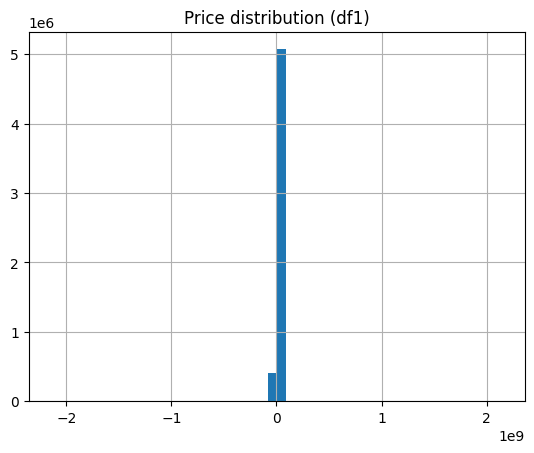

=== df2 ===
shape: (11358150, 1)
                                                       count    unique  \
date;price;level;levels;rooms;area;kitchen_area...  11358150  10961465   

                                                                                                  top  \
date;price;level;levels;rooms;area;kitchen_area...  2021-11-21;2393200;2;10;1;38.6;0;51.6718941;39...   

                                                   freq  
date;price;level;levels;rooms;area;kitchen_area...   51  
=== df3 ===
shape: (6983, 13)
                    count unique                                       top  \
price              6961.0    NaN                                       NaN   
min_to_metro       6846.0    NaN                                       NaN   
region_of_moscow     6892      9                                       ЦАО   
total_area         6960.0    NaN                                       NaN   
living_area        4514.0    NaN                                       

count    6.961000e+03
mean     5.991086e+07
std      9.353880e+07
min      8.000000e+05
25%      1.650000e+07
50%      3.050000e+07
75%      6.300000e+07
max      3.737636e+09
Name: price, dtype: float64

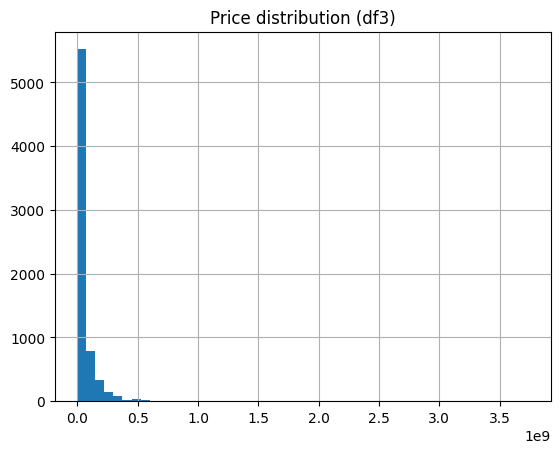

price            1.000000
area             0.121303
rooms            0.073896
kitchen_area     0.061908
levels           0.052906
level            0.040225
geo_lat          0.037456
building_type    0.007291
object_type      0.006498
geo_lon         -0.062832
region          -0.072897
Name: price, dtype: float64

In [ ]:
def basic_eda(df, name='df'):
    print('===', name, '===')
    print('shape:', df.shape)
    print(df.describe(include='all').T)
    if 'price' in df.columns:
        display(df['price'].describe())
        _ = df['price'].hist(bins=50)
        plt.title(f'Price distribution ({name})')
        plt.show()

basic_eda(df1, 'df1')
basic_eda(df2, 'df2')
basic_eda(df3, 'df3')

num_cols = df1.select_dtypes(include=[np.number]).columns.tolist()
if 'price' in num_cols:
    corrs = df1[num_cols].corr()['price'].sort_values(ascending=False)
    display(corrs.head(20))


In [ ]:

def preprocess_base(df):
    df = df.copy()
    df.columns = [c.lower() for c in df.columns]
    if 'price' in df.columns:
        df = df[df['price'] > 1000]
    if 'area' in df.columns and 'rooms' in df.columns:
        df['area_per_room'] = df['area'] / df['rooms'].replace(0, np.nan)
    if 'year_built' in df.columns:
        df['age'] = 2025 - df['year_built']
    if set(['latitude','longitude']).issubset(df.columns):
        center_lat, center_lon = 55.7539, 37.6208
        df['dist_to_center'] = np.sqrt((df['latitude']-center_lat)**2 + (df['longitude']-center_lon)**2)
    for c in df.columns:
        if df[c].dtype == 'object':
            df[c] = df[c].fillna('missing')
        else:
            df[c] = df[c].fillna(df[c].median())
    return df

df1_p = preprocess_base(df1)
df2_p = preprocess_base(df2)
df3_p = preprocess_base(df3)
display(df1_p.head())


,price,date,time,geo_lat,geo_lon,region,building_type,level,levels,rooms,area,kitchen_area,object_type,area_per_room
0,6050000,2018-02-19,20:00:21,59.805808,30.376141,2661,1,8,10,3,82.6,10.8,1,27.533333
1,8650000,2018-02-27,12:04:54,55.683807,37.297405,81,3,5,24,2,69.1,12.0,1,34.550000
2,4000000,2018-02-28,15:44:00,56.295250,44.061637,2871,1,5,9,3,66.0,10.0,1,22.000000
3,1850000,2018-03-01,11:24:52,44.996132,39.074783,2843,4,12,16,2,38.0,5.0,11,19.000000
4,5450000,2018-03-01,17:42:43,55.918767,37.984642,81,3,13,14,2,60.0,10.0,1,30.000000


In [ ]:
df = df3_p.copy()
candidate_features = []
for c in ['area','rooms','floor','floors_total','age','area_per_room','dist_to_center']:
    if c in df.columns:
        candidate_features.append(c)
print('Features used:', candidate_features)

TARGET = 'price'
df = df[df[TARGET].notnull()]
X = df[candidate_features]
y = df[TARGET].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.15, random_state=42)


Features used: ['floor']


In [ ]:
num_features = X_train.select_dtypes(include=[np.number]).columns.tolist()

num_pipeline = Pipeline([('scaler', StandardScaler())])
preprocessor = ColumnTransformer(transformers=[('num', num_pipeline, num_features)])

lr_pipe = Pipeline([('preproc', preprocessor),
                    ('lr', LinearRegression())])
lr_pipe.fit(X_train, y_train)
pred_lr = lr_pipe.predict(X_test)

print('LinearRegression RMSE:', mean_squared_error(y_test, pred_lr) ** 0.5)
print('LinearRegression MAE:', mean_absolute_error(y_test, pred_lr))

if 'xgboost' in globals():
    xgb_model = xgb.XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=6, random_state=42, verbosity=0)
    xgb_model.fit(X_train, y_train, eval_set=[(X_test,y_test)], early_stopping_rounds=50, verbose=False)
    pred_xgb = xgb_model.predict(X_test)
    print('XGBoost RMSE:', mean_squared_error(y_test, pred_xgb) ** 0.5)


LinearRegression RMSE: 139523901.087584
LinearRegression MAE: 53272559.34318946


In [ ]:
from sklearn.ensemble import StackingRegressor

estimators = [
    ('ridge', Ridge(alpha=1.0)),
]

if 'lgb' in globals():
    estimators.append(('lgb', lgb.LGBMRegressor(n_estimators=1000)))

if 'xgboost' in globals():
    estimators.append(('xgb', xgb.XGBRegressor(
        n_estimators=1000,
        learning_rate=0.05
    )))

if 'ctb' in globals():
    estimators.append(('cat', ctb.CatBoostRegressor(
        verbose=0,
        iterations=1000
    )))

stack = StackingRegressor(
    estimators=estimators,
    final_estimator=Ridge()
)

stack.fit(X_train, y_train)
pred_stack = stack.predict(X_test)

rmse_stack = mean_squared_error(y_test, pred_stack) ** 0.5
print('Stack RMSE:', rmse_stack)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000227 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 68
[LightGBM] [Info] Number of data points in the train set: 5916, number of used features: 1
[LightGBM] [Info] Start training from score 59841432.547160
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000120 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 66
[LightGBM] [Info] Number of data points in the train set: 4732, number of used features: 1
[LightGBM] [Info] Start training from score 60403134.554945
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000090 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 65
[LightGBM] [Info] Number of data points in the train set: 4733, number of used features: 1
[LightGBM] [Info] Start t

Base models found: ['ridge', 'lgb', 'cat']
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000366 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 65
[LightGBM] [Info] Number of data points in the train set: 4732, number of used features: 1
[LightGBM] [Info] Start training from score 59535684.603762
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000150 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 67
[LightGBM] [Info] Number of data points in the train set: 4733, number of used features: 1
[LightGBM] [Info] Start training from score 60282397.628354
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000168 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 66
[LightGBM] [Info] Number of data points in the train set: 4733, number of

C:\Users\Stefan\AppData\Roaming\Python\Python312\site-packages\shap\explainers\_linear.py:99: FutureWarning: The feature_perturbation option is now deprecated in favor of using the appropriate masker (maskers.Independent, maskers.Partition or maskers.Impute).
  warnings.warn(wmsg, FutureWarning)


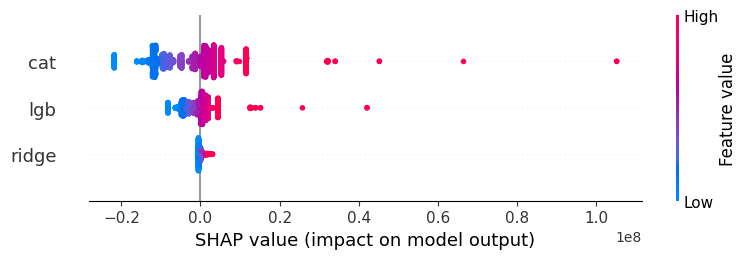

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold
from sklearn.base import clone
import shap
from copy import deepcopy

if hasattr(stack, "named_estimators_"):
    named = stack.named_estimators_
else:
    named = {name: est for name, est in stack.estimators_}

print("Base models found:", list(named.keys()))

if not isinstance(X_train, pd.DataFrame):
    X_train = pd.DataFrame(X_train, columns=[f"f{i}" for i in range(X_train.shape[1])])
if not isinstance(X_test, pd.DataFrame):
    X_test = pd.DataFrame(X_test, columns=X_train.columns)

y_arr = np.array(y_train)

def get_oof_predictions(models_dict, X, y, n_splits=5):
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)
    oof_preds = {name: np.zeros(len(X)) for name in models_dict.keys()}
    for fold, (tr_idx, val_idx) in enumerate(kf.split(X, y)):
        X_tr, X_val = X.iloc[tr_idx], X.iloc[val_idx]
        y_tr = y[tr_idx]
        for name, model in models_dict.items():
            m = clone(model)                 
            try:
                m.fit(X_tr, y_tr)
            except Exception as e:
                print(f"Fit failed for {name} on fold {fold}: {e}")
                m = deepcopy(model)
                m.fit(X_tr, y_tr)
            preds = m.predict(X_val)
            oof_preds[name][val_idx] = preds
    meta_df = pd.DataFrame(oof_preds, index=X.index)
    return meta_df

meta_X_train = get_oof_predictions(named, X_train.reset_index(drop=True), y_arr, n_splits=5)

meta_X_test = pd.DataFrame({
    name: clone(model).fit(X_train.reset_index(drop=True), y_arr).predict(X_test.reset_index(drop=True))
    for name, model in named.items()
}, index=X_test.index)

print("Meta train shape:", meta_X_train.shape)
print("Meta test shape:", meta_X_test.shape)

final = stack.final_estimator_
try:
    final.fit(meta_X_train, y_arr)
except Exception as e:
    final = clone(final)
    final.fit(meta_X_train, y_arr)

explainer = shap.LinearExplainer(final, meta_X_train, feature_perturbation="interventional")
shap_values = explainer.shap_values(meta_X_test)

shap.summary_plot(shap_values, meta_X_test, feature_names=meta_X_test.columns)
